In [ ]:
!pip install importlib_resources #INSTALAMOS COMPLEMENTO PARA ACCEDER A RECURSOS DEL DATASET

In [ ]:
import tensorflow as tf
import tensorflow_datasets as tfds
import matplotlib.pyplot as plt

In [ ]:
ds= tfds.load('oxford_iiit_pet')

Dl Completed...: 0 url [00:00, ? url/s]

Dl Size...: 0 MiB [00:00, ? MiB/s]

Extraction completed...: 0 file [00:00, ? file/s]

Generating splits...:   0%|          | 0/2 [00:00<?, ? splits/s]

Generating train examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/oxford_iiit_pet/incomplete.65PSG6_4.0.0/oxford_iiit_pet-train.tfrecord-[0-…

Generating test examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/oxford_iiit_pet/incomplete.65PSG6_4.0.0/oxford_iiit_pet-test.tfrecord-[0-9…

Dataset oxford_iiit_pet downloaded and prepared to /root/tensorflow_datasets/oxford_iiit_pet/4.0.0. Subsequent calls will reuse this data.


In [ ]:
NOMBRES=['gato','perro']
print(NOMBRES)

['gato', 'perro']


In [ ]:
def preparar(d):
  img= tf.image.resize(d['image'], (128,128))/255 #Modificamos el tamaño de la imagen y la normalizamos
  return img, d['species'] #Retornamos la imagen y su respectiva etiqueta

In [ ]:
train= ds['train'].map(preparar).shuffle(1000).batch(32)
test= ds['test'].map(preparar).shuffle(1000).batch(32)

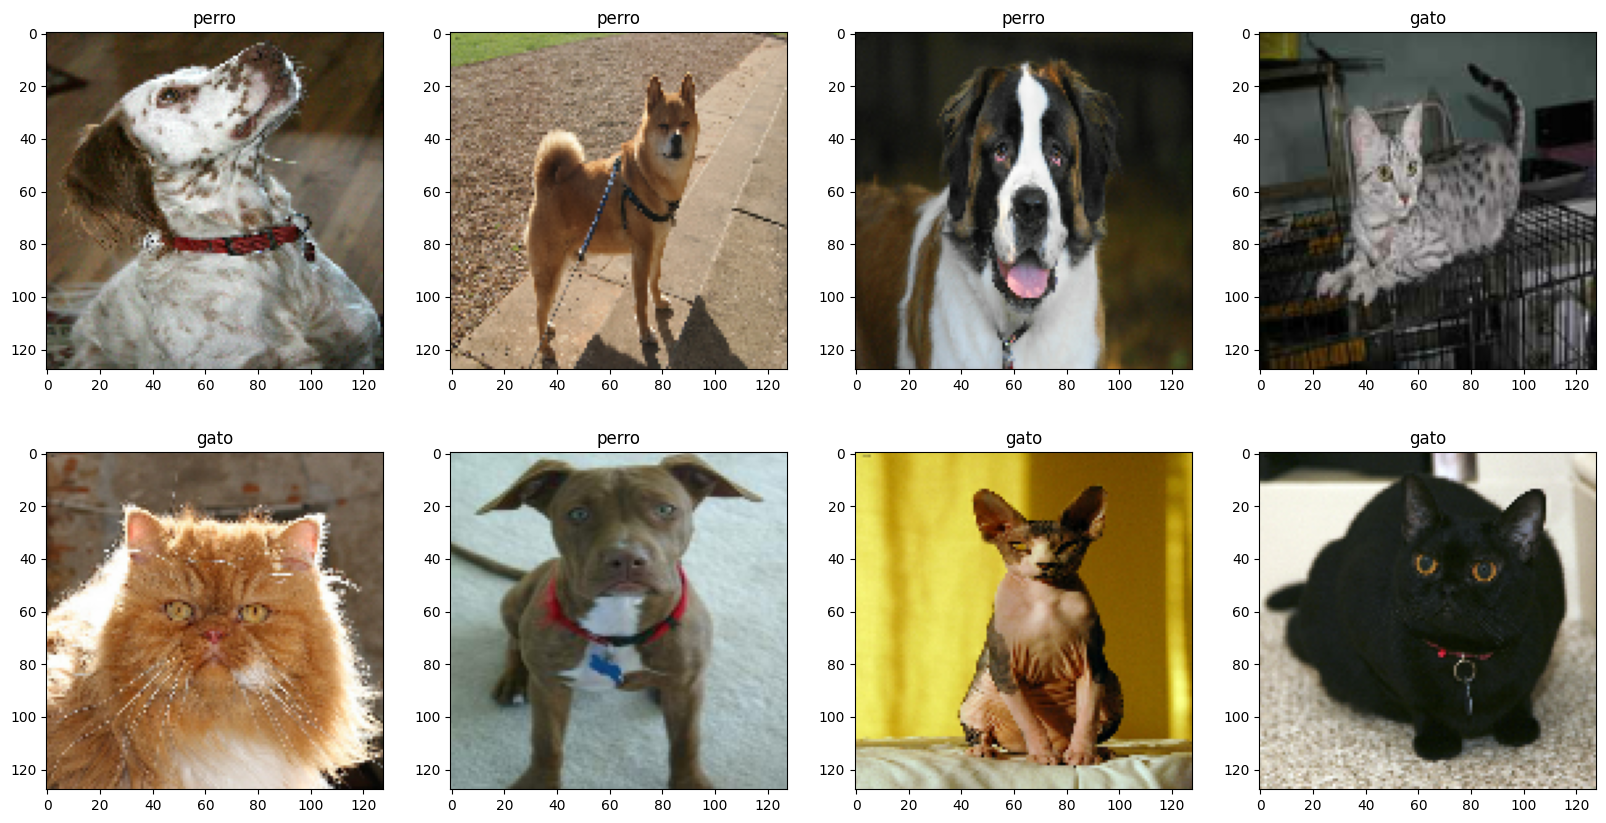

In [ ]:
plt.figure(figsize=(20,10))
for i, (img, y) in enumerate(ds['train'].map(preparar).shuffle(100).take(8)):
  plt.subplot(2,4,i+1)
  plt.imshow(img)
  plt.title(NOMBRES[y])

In [ ]:
model= tf.keras.models.Sequential([
    tf.keras.layers.Input(shape=(128,128,3)),
    tf.keras.layers.Conv2D(16, 3, activation='relu'),
    tf.keras.layers.MaxPooling2D(),
    tf.keras.layers.Conv2D(32, 3, activation='relu'),
    tf.keras.layers.MaxPooling2D(),
    tf.keras.layers.Conv2D(64, 3, activation='relu'),
    tf.keras.layers.MaxPooling2D(),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(64, activation='relu'),
    tf.keras.layers.Dense(1, activation='sigmoid')
])
model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

In [ ]:
model.fit(train, epochs=5, validation_data= test)

Epoch 1/5
115/115 ━━━━━━━━━━━━━━━━━━━━ 25s 136ms/step - accuracy: 0.6690 - loss: 0.6348 - val_accuracy: 0.6776 - val_loss: 0.5736
Epoch 2/5
115/115 ━━━━━━━━━━━━━━━━━━━━ 16s 122ms/step - accuracy: 0.7033 - loss: 0.5699 - val_accuracy: 0.7220 - val_loss: 0.5427
Epoch 3/5
115/115 ━━━━━━━━━━━━━━━━━━━━ 17s 134ms/step - accuracy: 0.7304 - loss: 0.5223 - val_accuracy: 0.7422 - val_loss: 0.5133
Epoch 4/5
115/115 ━━━━━━━━━━━━━━━━━━━━ 16s 121ms/step - accuracy: 0.7905 - loss: 0.4548 - val_accuracy: 0.7533 - val_loss: 0.5350
Epoch 5/5
115/115 ━━━━━━━━━━━━━━━━━━━━ 16s 119ms/step - accuracy: 0.8120 - loss: 0.4109 - val_accuracy: 0.7618 - val_loss: 0.4970


In [ ]:
imgs, etiquetas= next(iter(test))
probs= model.predict(imgs[:8], verbose=0).flatten()
print(etiquetas[:8])
print(probs.round().astype(int))

tf.Tensor([0 0 1 1 0 1 1 1], shape=(8,), dtype=int64)
[0 0 1 1 0 1 1 1]


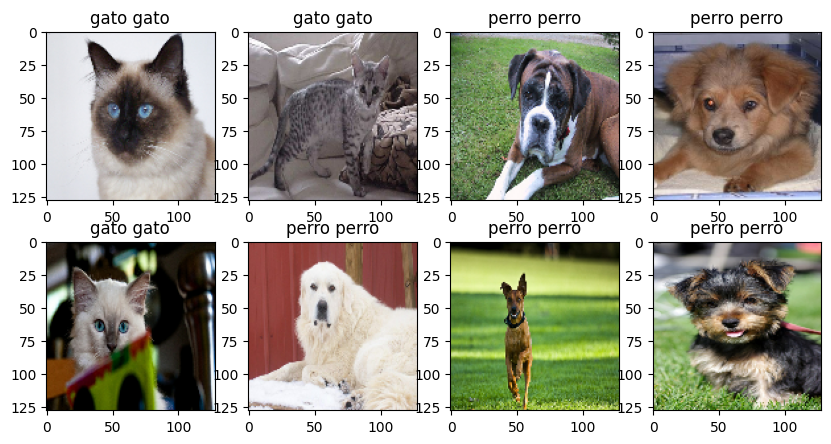

In [ ]:
plt.figure(figsize=(10,5))
for i in range(8):
  plt.subplot(2,4,i+1)
  plt.imshow(imgs[i])
  plt.title(str(NOMBRES[etiquetas[i]])+ ' ' + str(NOMBRES[probs.round().astype(int)[i]]))